# **Задание: Оценка эффекта строительства тюрем в Техасе с использованием метода синтетического контроля**

---

## **1. Контекст исследования**

### **Историческая справка**

В 1980 году Техасский департамент исправительных учреждений (Texas Department of Corrections, TDC) проиграл гражданский иск *Ruiz v. Estelle*. Иск был подан заключенным по имени Руис против начальника тюрьмы Эстелла. В иске утверждалось, что условия содержания в тюрьмах Техаса нарушают конституционные права заключенных, особенно в части переполненности камер и антисанитарных условий.

Суд принял сторону истца, и Техас был вынужден подписать серию соглашений. Для решения проблемы переполненности суд ввел ограничения на максимальное количество заключенных, которые могут содержаться в каждой камере. Чтобы обеспечить соблюдение этих требований, TDC был помещен под надзор суда до 2003 года.

В этих условиях у властей Техаса было два пути:
1. **Строительство новых тюрем** — чтобы увеличить мощность системы и продолжать арестовывать преступников в прежних масштабах
2. **Увеличение числа условно-досрочных освобождений** — чтобы снизить нагрузку на существующие тюрьмы

Изначально Техас пошел по второму пути. После решения по делу *Ruiz v. Estelle* штат начал активнее использовать условно-досрочное освобождение.

Однако в конце 1980-х годов губернатор Билл Клементс начал программу строительства новых тюрем. Позже, в 1993 году, губернатор Энн Ричардс запустила беспрецедентную по масштабам программу расширения пенитенциарной системы. При Ричардс законодатели Техаса одобрили выделение **$1 миллиарда** на строительство тюрем, что позволило удвоить мощность системы всего за три года.

### **Исследовательский вопрос**

Как строительство новых тюрем при губернаторе Энн Ричардс повлияло на уровень incarceration (тюремного заключения) чернокожих мужчин в Техасе?


### **Цель задания**

Вам предстоит:
1. Применить метод синтетического контроля (Synthetic Control Method) для оценки causal эффекта строительства тюрем
2. Создать синтетический Техас — взвешенную комбинацию других штатов, максимально похожую на Техас до 1993 года
3. Сравнить фактический Техас с синтетическим контролем после 1993 года
4. Оценить величину и значимость эффекта вмешательства

---

## **2. Описание данных**

### **Структура данных**

Данные представляют собой панель по штатам США за период **1985–2000 годы**. Единица наблюдения — штат в определенном году.

**Таблица 1. Описание переменных**

| Переменная | Тип | Описание |
|------------|-----|----------|
| **`statefip`** | Целочисленный | FIPS-код штата (уникальный идентификатор). Техас имеет код 48. |
| **`state`** | Строковый | Название штата (например, "Texas", "California", "New York"). |
| **`year`** | Целочисленный | Год наблюдения. Диапазон: 1985–2000. |
| **`bmprison`** | Числовой с плавающей точкой | **Зависимая переменная.** Уровень incarceration чернокожих мужчин (тюремное заключение на душу населения). Ключевой показатель исследования. |
| **`poverty`** | Числовой с плавающей точкой | Уровень бедности в штате (доля населения за чертой бедности). Используется как предиктор для построения синтетического контроля. |
| **`income`** | Числовой с плавающей точкой | Доход на душу населения в штате. Используется как предиктор. |
| **`alcohol`** | Числовой с плавающей точкой | Потребление алкоголя на душу населения. Специальный предиктор, учитываемый за определенные годы. |
| **`aidscapita`** | Числовой с плавающей точкой | Количество зарегистрированных случаев СПИДа на душу населения. Специальный предиктор, отражающий эпидемиологическую ситуацию. |
| **`black`** | Числовой с плавающей точкой | Доля чернокожего населения в штате. Важный демографический предиктор. |
| **`perc1519`** | Числовой с плавающей точкой | Доля населения в возрастной группе 15–19 лет. Учитывает возрастную структуру, важную для преступности. |

### **Периоды анализа**

На основе исторического контекста в исследовании выделяются следующие периоды:

| Период | Годы | Назначение |
|--------|------|------------|
| **Донорный период (pre-treatment)** | 1985–1992 | Период, используемый для подбора весов контрольных единиц. Синтетический Техас должен максимально точно воспроизводить траекторию реального Техаса в эти годы. |
| **Момент вмешательства** | 1993 | Год, когда губернатор Энн Ричардс начала масштабное строительство тюрем. Вертикальная линия на графиках. |
| **Пост-период (post-treatment)** | 1993–2000 | Период оценки эффекта. Разрыв между реальным Техасом и синтетическим контролем интерпретируется как causal эффект вмешательства. |

### **Задача**

Оценить размер и стат. значимость влияния воздействия в штате **Техас** (statefip = 48)


In [ ]:
!pip install SyntheticControlMethods

  Preparing metadata (setup.py) ... done
  Created wheel for SyntheticControlMethods: filename=SyntheticControlMethods-1.1.17-py2.py3-none-any.whl size=27887 sha256=647edfd9fbcbbb8be009cb2d25be67f2c04e0cb905a367548210519b67dc037a
  Stored in directory: /root/.cache/pip/wheels/6f/59/26/13c508416e04b638f32f0bc523cbe952d7868911309395e6c8
Successfully built SyntheticControlMethods


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from SyntheticControlMethods import Synth

In [2]:
df = pd.read_csv("texas.csv")

print(df.head())
print(df.info())
print(df.describe())

   statefip    year  bmprison  poverty  income  alcohol  aidscapita  \
0       1.0  1985.0    6227.0     20.6   11566     1.90    0.679504   
1       1.0  1986.0    6657.0     23.8   12164     1.90    0.851692   
2       1.0  1987.0    7281.0     21.3   12826     1.89    1.967214   
3       1.0  1988.0    7244.0     19.3   13698     1.89    2.758137   
4       1.0  1989.0    8056.0     18.9   14865     1.87    3.845907   

       black  perc1519  
0  25.866339  8.461768  
1  25.827267  8.473580  
2  25.777328  8.397089  
3  25.734392  8.280076  
4  25.694050  8.088959  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 816 entries, 0 to 815
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   statefip    816 non-null    float64
 1   year        816 non-null    float64
 2   bmprison    816 non-null    float64
 3   poverty     816 non-null    float64
 4   income      816 non-null    int64  
 5   alcohol     816 non-null   

In [3]:
treated_state = 48

#df["treated"] = (df["statefip"] == treated_state).astype(int)

In [4]:
outcome_var = "bmprison"

predictors = [
    "poverty",
    "income",
    "alcohol",
    "aidscapita",
    "black",
    "perc1519"
]

In [5]:
pre_df = df[df["year"] <= 1992]

summary = pre_df.groupby("statefip")[predictors].mean()

texas_summary = summary.loc[48]
others_summary = summary.drop(48).mean()

comparison = pd.DataFrame({
    "Texas": texas_summary,
    "Donor_mean": others_summary
})

print(comparison)

                   Texas    Donor_mean
poverty        17.200000     13.392250
income      16108.625000  17080.345000
alcohol         2.511250      2.516850
aidscapita     10.047528      6.620288
black          16.020101     11.412447
perc1519        7.879619      7.466546


In [6]:

df = df[
    [
        "statefip",
        "year",
        "bmprison",
        "poverty",
        "income",
        "alcohol",
        "aidscapita",
        "black",
        "perc1519"
    ]
].copy()

df = df.dropna()

df = df.drop_duplicates(["statefip","year"])

df = df.sort_values(["statefip","year"])

# 1. Общий сравнительный анализ

В качестве первичной аналитики сравним показатель тюремного заключения до и после начала кампании по строительству тюрем в Техасе и в остальных городах, так мы постараемся понять, насколько выражены изменения.

In [7]:
df = df.pivot(index='year', columns='statefip', values='bmprison').reset_index()

In [8]:
treated_state = 48
states = [c for c in df.columns if c!='year']
df['Other States'] = df[[c for c in states if c != treated_state]].mean(axis=1)

In [ ]:
df

statefip,year,1.0,2.0,4.0,5.0,6.0,8.0,9.0,10.0,11.0,...,47.0,48.0,49.0,50.0,51.0,53.0,54.0,55.0,56.0,Other States
0,1985.0,6227.0,198.0,1297.0,2153.0,16138.0,665.0,2620.0,1356.0,6021.0,...,3045.0,14828.0,142.0,0.0,6825.0,1218.0,244.0,1954.0,33.0,3789.04
1,1986.0,6657.0,211.0,1452.0,2238.0,19549.0,786.0,2890.0,1545.0,6241.0,...,3000.0,15207.0,143.0,0.0,7291.0,1182.0,201.0,2136.0,32.0,4129.92
2,1987.0,7281.0,217.0,1675.0,2536.0,22184.0,959.0,3070.0,1595.0,7126.0,...,3019.0,15780.0,161.0,0.0,7488.0,1129.0,200.0,2234.0,30.0,4409.18
3,1988.0,7244.0,271.0,1775.0,2646.0,26438.0,1229.0,3541.0,1823.0,8205.0,...,2972.0,16956.0,167.0,0.0,8239.0,1225.0,199.0,2244.0,52.0,4872.16
4,1989.0,8056.0,310.0,2033.0,3126.0,30066.0,1492.0,4172.0,2045.0,9320.0,...,4364.0,19366.0,196.0,0.0,9739.0,1315.0,211.0,2501.0,51.0,5598.42
5,1990.0,9282.0,288.0,2283.0,3648.5,32190.0,1525.0,4818.0,2102.0,9222.0,...,4428.0,22634.0,208.0,0.0,10617.0,1489.0,215.0,2783.0,49.0,6098.23
6,1991.0,10119.0,314.0,2432.0,4171.0,32981.0,1801.0,4856.0,2287.0,9513.0,...,5287.0,23249.0,207.0,0.0,12109.0,1810.0,208.0,3148.0,48.0,6560.48
7,1992.0,10660.0,327.0,2654.0,4449.0,34279.0,1912.0,4897.0,2476.0,9996.0,...,5586.0,27568.0,234.0,0.0,12896.0,2036.0,239.0,3775.0,48.0,6971.66
8,1993.0,11450.0,313.0,2865.0,4642.0,36461.0,2152.0,5873.0,2606.0,10023.0,...,5965.0,29260.0,230.0,0.0,14093.0,2096.0,257.0,3908.0,53.0,7450.92
9,1994.0,11996.0,415.0,3085.0,4612.0,37472.0,2364.0,6175.0,2797.0,10129.0,...,6918.0,40451.0,253.0,29.0,17002.0,2278.0,274.0,4577.0,55.0,8021.64


In [9]:
def plot_lines(df, line1, line2, year, hline=True):
    sns.lineplot(x=df['year'], y=df[line1].values, label=line1)
    sns.lineplot(x=df['year'], y=df[line2].values, label=line2)
    plt.axvline(x=year, ls=":", color='C2', label='Строительство тюрем', zorder=1)
    plt.legend();
    plt.title("Уровень incarceration чернокожих мужчин");

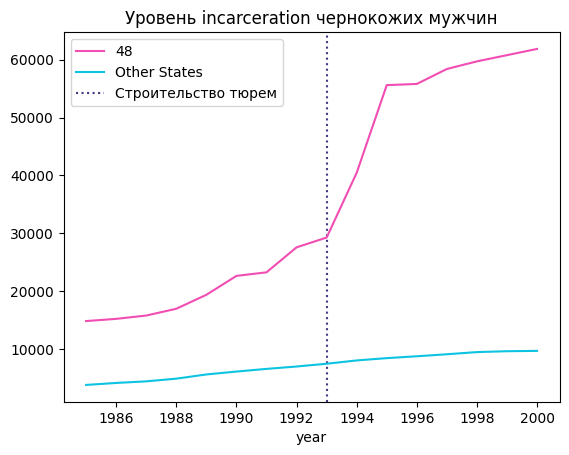

In [10]:
treatment_year = 1993

sns.set_palette(sns.color_palette(['#f14db3', '#0dc3e2', '#443a84']))
plot_lines(df, treated_state, 'Other States', treatment_year)

После нововведения уровень тюремного заключения, по всей видимости, растет. Но и до начала кампании по строительсву тюрем, уровень заключения был выше, чем в остальных городах. Также в остальной части страны показатель также рос. Судя по этому графику, изменения трудно отнести только к строительству, требуется более глубокий анализ.



## 1.2 Оценка с помощью линейной регрессии
Предскажем, каким был бы уровень тюремного заключения в Техасе без нововведения с помощью метода линейной регрессии. Функция synth_predict использует входные данные из модели, обученной на контрольных городах (всех кроме Техаса), и пытается составить из них линейную комбинацию, приближенную к Техасу

In [11]:
def synth_predict(df, model, state, year):
    other_states = [c for c in states if c not in ['year', state]]
    y = df.loc[df['year'] <= year, state]
    X = df.loc[df['year'] <= year, other_states]
    df[f'Synthetic {state}'] = model.fit(X, y).predict(df[other_states])
    return model

from sklearn.linear_model import LinearRegression
coef = synth_predict(df, LinearRegression(), treated_state, treatment_year).coef_

In [ ]:
coef

array([ 9.30702430e-02, -1.19652116e-02,  8.23593056e-02,  5.67587619e-02,
       -7.39227843e-02, -1.39254207e-01,  7.44645797e-03, -1.49390386e-02,
        8.75151715e-02,  9.89428177e-03,  3.77926107e-02,  1.85750060e-03,
       -6.23344402e-03,  1.03564532e+00,  3.23115784e-01,  6.06117204e-02,
        6.07039361e-03,  2.16396403e-03,  2.32696646e-01, -7.25436851e-04,
        5.39238408e-01,  2.55612789e-01,  3.74204939e-01, -1.06044540e-02,
       -2.72476225e-01,  2.21106329e-01,  6.71340736e-04, -1.53549579e-02,
        4.44819206e-02, -1.09144999e-02, -6.54764262e-01,  2.08862500e-02,
        6.09198426e-02,  7.84444063e-01,  2.14146519e-03, -6.81118754e-01,
        2.08507931e-01, -7.40302086e-02,  3.52943093e-01, -7.04711394e-02,
        2.07842339e-01,  1.19047264e-02, -3.42533074e-01,  2.50623502e-02,
        0.00000000e+00, -2.38490227e-01,  8.62155155e-02,  4.07506031e-02,
        2.94410521e-01,  1.64696408e-03])

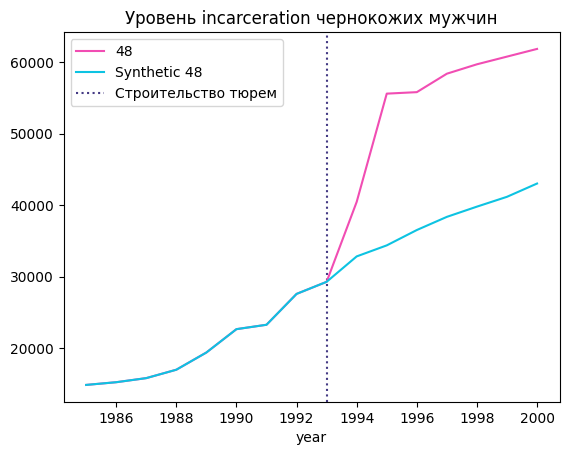

In [ ]:
plot_lines(df, treated_state, f'Synthetic {treated_state}', treatment_year)


Судя по всему, построение тюрем оказало ощутимое положительное влияние на метрику: прогнозируемый тренд сильно ниже реальных данных

# 2. Подбор весовых коэффициентов для ситетического контроля

Наша цель состоит в том, чтобы составить взвешенную комбинацию из штатов, которая будет похожа на Техас. Для этого оценим весовые коэффициенты штатов.

Мы используем метод линейной регрессии, рассмотренный как подходящий для задачи в статье https://arxiv.org/pdf/1610.07748. Согласно ней,  весовые коэффициенты должны быть таковы, что они минимизируют расстояние между наблюдаемыми признаками контрольных и исследуемых объектов до вмешательства.


In [12]:
df_states = pd.DataFrame({'state': [c for c in states if c!=treated_state], 'ols_coef': coef})

/tmp/ipykernel_67978/1156502304.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_states, x='ols_coef', y='state', orient="h", palette=colors)
/tmp/ipykernel_67978/1156502304.py:5: UserWarning: Numpy array is not a supported type for `palette`. Please convert your palette to a list. This will become an error in v0.14
  sns.barplot(data=df_states, x='ols_coef', y='state', orient="h", palette=colors)


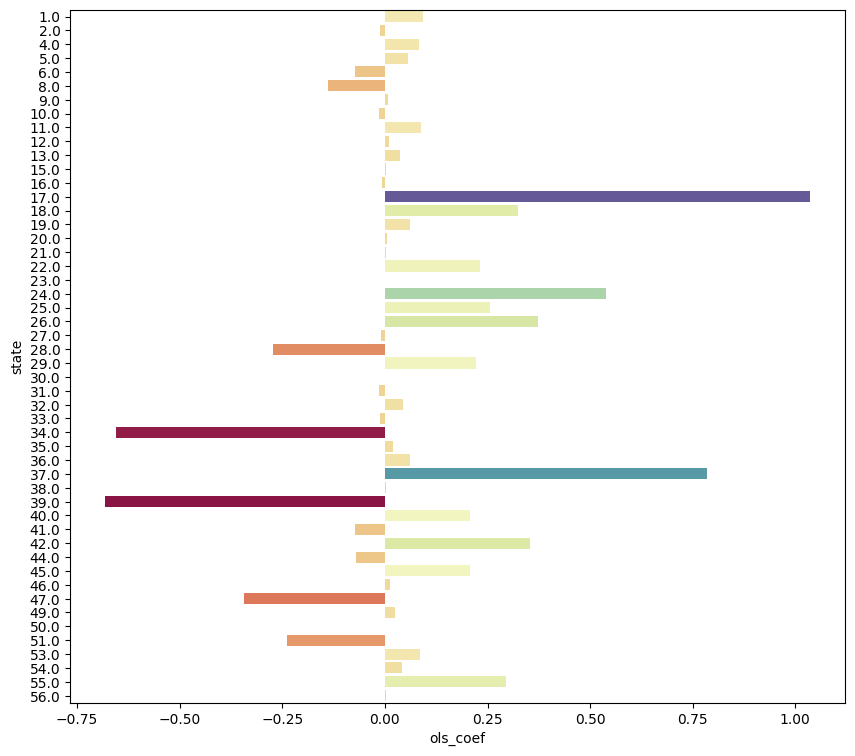

In [13]:
plt.figure(figsize=(10, 9))

norm = plt.Normalize(df_states['ols_coef'].min(), df_states['ols_coef'].max())
colors = plt.cm.Spectral(norm(df_states['ols_coef']))
sns.barplot(data=df_states, x='ols_coef', y='state', orient="h", palette=colors)

plt.show()

Теперь составим комбинацию из штатов с их весовыми коэффициентами такую, которая была бы похожа на Техас, и сравним значения уровня заключений в тесте и в контроле.

In [14]:
from toolz import partial
from scipy.optimize import fmin_slsqp

class SyntheticControl():

    # Loss function
    def loss(self, W, X, y) -> float:
        return np.sqrt(np.mean((y - X.dot(W))**2))

    # Fit model
    def fit(self, X, y):
        w_start = [1/X.shape[1]]*X.shape[1]
        self.coef_ = fmin_slsqp(partial(self.loss, X=X, y=y),
                         np.array(w_start),
                         f_eqcons=lambda x: np.sum(x) - 1,
                         bounds=[(0.0, 1.0)]*len(w_start),
                         disp=False)
        self.mse = self.loss(W=self.coef_, X=X, y=y)
        return self

    # Predict
    def predict(self, X):
        return X.dot(self.coef_)

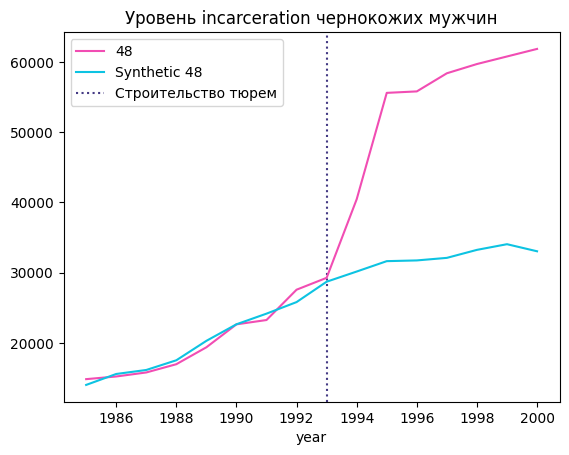

In [15]:
treatment_year = 1993
treated_state = 48

df_states['coef_synth'] = synth_predict(df, SyntheticControl(), treated_state, treatment_year).coef_
plot_lines(df, treated_state, f'Synthetic {treated_state}', treatment_year)

Эти результаты выглядят гораздо более реалистичными, чем первое сравнение.

Так как мы не можем интерпретировать отрицательные коэффиценты для городов составим максимально приближенную комбинацию из положительных:

/tmp/ipykernel_29456/2064429111.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_states, x='coef_synth', y='state', orient="h", palette=colors)
/tmp/ipykernel_29456/2064429111.py:5: UserWarning: Numpy array is not a supported type for `palette`. Please convert your palette to a list. This will become an error in v0.14
  sns.barplot(data=df_states, x='coef_synth', y='state', orient="h", palette=colors)


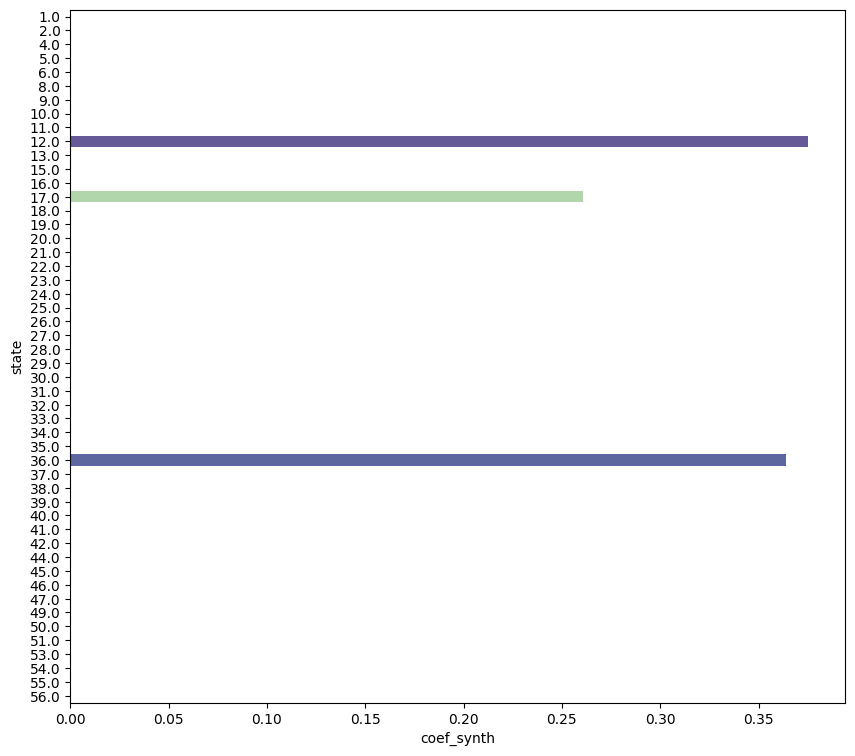

In [ ]:
plt.figure(figsize=(10, 9))

norm = plt.Normalize(df_states['coef_synth'].min(), df_states['coef_synth'].max())
colors = plt.cm.Spectral(norm(df_states['coef_synth']))
sns.barplot(data=df_states, x='coef_synth', y='state', orient="h", palette=colors)

plt.show()


## 2.1 Оценка эффекта

Посчитаем величину эффекта, оказанного строительством тюрем, относительно этого контроля. Считаем его через количество доп. заключений, полученных в тесте

In [19]:
import numpy as np
import pandas as pd
from toolz import partial
from scipy.optimize import fmin_slsqp

def calculate_cumulative_effect(df, treated_state, treatment_year):

    synth_col = f'Synthetic {treated_state}'

    if synth_col not in df.columns:
        raise ValueError(f"Колонка '{synth_col}' не найдена. Сначала запустите synth_predict()")

    post_treatment = df[df['year'] > treatment_year].copy()

    if len(post_treatment) == 0:
        raise ValueError(f"Нет данных после {treatment_year} года")

    post_treatment['difference'] = post_treatment[treated_state] - post_treatment[synth_col]

    cumulative_effect = post_treatment['difference'].sum()

    avg_annual_effect = post_treatment['difference'].mean()

    stats = {
        'treated_state': treated_state,
        'treatment_year': treatment_year,
        'years_analyzed': len(post_treatment),
        'cumulative_effect': cumulative_effect,
        'avg_annual_effect': avg_annual_effect,
        'min_difference': post_treatment['difference'].min(),
        'max_difference': post_treatment['difference'].max(),
        'std_difference': post_treatment['difference'].std()
    }

    return stats, post_treatment


treatment_year = 1993
treated_state = 48

model = synth_predict(df, SyntheticControl(), treated_state, treatment_year)

weights = model.coef_

stats, post_df = calculate_cumulative_effect(df, treated_state, treatment_year)


print(f"Суммерное изменение (в кол-ве доп. заключений): {stats['cumulative_effect']:,.2f}")
print(f"Среднегодовой эффект: {stats['avg_annual_effect']:,.2f}")
print(f"Стандартное отклонение: {stats['std_difference']:,.2f}")


print("\nПогодовая разница")
print(post_df[['year', treated_state, f'Synthetic {treated_state}', 'difference']].to_string(index=False))


Суммерное изменение (в кол-ве доп. заключений): 166,654.51
Среднегодовой эффект: 23,807.79
Стандартное отклонение: 6,186.37

Погодовая разница
  year    48.0  Synthetic 48   difference
1994.0 40451.0  30155.057347 10295.942653
1995.0 55602.0  31633.615055 23968.384945
1996.0 55810.0  31737.617692 24072.382308
1997.0 58393.0  32101.338189 26291.661811
1998.0 59709.0  33241.033324 26467.966676
1999.0 60785.0  34048.276400 26736.723600
2000.0 61861.0  33039.552671 28821.447329


## 2.2 Сравнение с остальными штатами

Синтезируем перидов после 1993 для всех штатов кроме Техаса и смотрим на отличия между отклонением кол-ва заключений с и без синтезирования.

Если вмешательство не имеет эффекта, то линия для Техаса не должна сильно отличаться от линий других штатов.

In [ ]:
def plot_lines2(df, line1, line2, year, hline=True, ax=None):
    if ax is None:
        ax = plt.gca()  # Если ось не передана, берем текущую

    sns.lineplot(x=df['year'], y=df[line1].values, label=line1, ax=ax)
    sns.lineplot(x=df['year'], y=df[line2].values, label=line2, ax=ax)
    ax.axvline(x=year, ls=":", color='C2', label='Строительство тюрем', zorder=1)
    ax.legend()
    ax.set_title("Уровень incarceration чернокожих мужчин")
    ax.grid(True, alpha=0.3)

treated_state = '48.0' (тип: <class 'str'>)
Всего штатов: 51
Есть ли '48.0' в списке: True


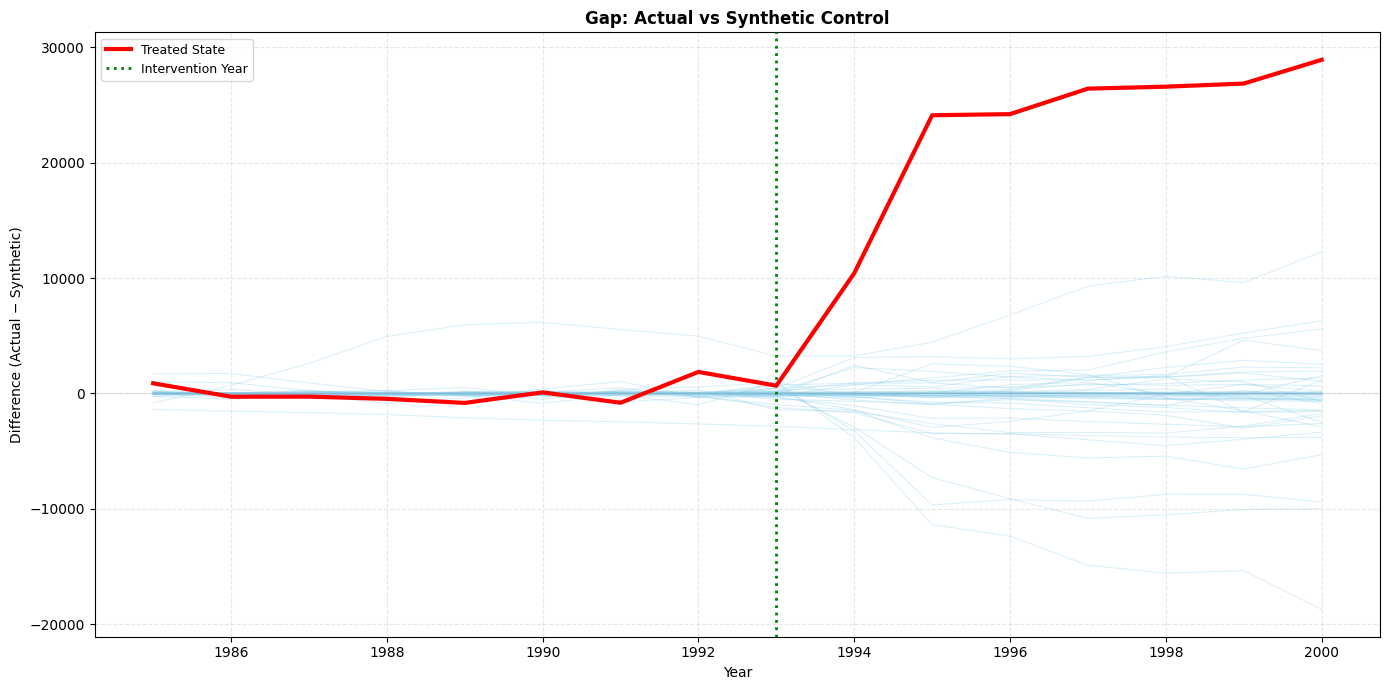

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from functools import partial

df1 = pd.read_csv("texas.csv")
df1 = df1[["statefip", "year", "bmprison", "poverty", "income", "alcohol", "aidscapita", "black", "perc1519"]].copy()
df1 = df1.dropna()
df1 = df1.drop_duplicates(["statefip", "year"])

df1['statefip'] = df1['statefip'].astype(str)

treated_state = str(48.0)


# Список всех штатов
all_states = sorted(df1['statefip'].unique().tolist())

print(f"treated_state = '{treated_state}' (тип: {type(treated_state)})")
print(f"Всего штатов: {len(all_states)}")
print(f"Есть ли '{treated_state}' в списке: {treated_state in all_states}")

class SyntheticControl:
    def __init__(self):
        self.coef_ = None
        self.mse = None

    def loss(self, W, X, y):
        prediction = X.dot(W)
        return np.sqrt(np.mean((y - prediction)**2))

    def fit(self, X, y):
        X = np.asarray(X)
        y = np.asarray(y).flatten()

        n_donors = X.shape[1]
        w_start = np.ones(n_donors) / n_donors

        constraints = {'type': 'eq', 'fun': lambda x: np.sum(x) - 1}
        bounds = [(0.0, 1.0)] * n_donors

        res = minimize(partial(self.loss, X=X, y=y),
                       x0=w_start,
                       method='SLSQP',
                       bounds=bounds,
                       constraints=constraints,
                       options={'disp': False})

        self.coef_ = res.x
        self.mse = self.loss(self.coef_, X, y)
        return self


def calculate_difference(df, target_state, treatment_year, outcome_col='bmprison'):

    df_target_pre = df[(df['statefip'] == target_state) & (df['year'] < treatment_year)]

    if len(df_target_pre) == 0:
        raise ValueError(f"Нет данных до {treatment_year} для штата {target_state}")

    y = df_target_pre[outcome_col].values

    df_donors_pre = df[(df['statefip'] != target_state) & (df['year'] < treatment_year)]
    X_pre = df_donors_pre.pivot(index='year', columns='statefip', values=outcome_col)


    common_years = df_target_pre['year'].values
    X_pre = X_pre.loc[common_years]

    model = SyntheticControl()
    model.fit(X_pre.values, y)

    donor_columns = X_pre.columns.tolist()

    df_target_all = df[df['statefip'] == target_state].sort_values('year')
    df_donors_all = df[df['statefip'] != target_state].sort_values('year')

    differences = []
    for _, row in df_target_all.iterrows():
        yr = row['year']
        actual = row[outcome_col]

        donors_vals = df_donors_all[df_donors_all['year'] == yr].pivot(index='year', columns='statefip', values=outcome_col)

        if not donors_vals.empty and yr in donors_vals.index:
            X_row = donors_vals.loc[yr].reindex(donor_columns).values
            if not np.any(np.isnan(X_row)):
                synthetic = np.dot(X_row, model.coef_)
                differences.append({
                    'year': yr,
                    'state': target_state,
                    'difference': actual - synthetic,
                    'is_treated': (str(target_state) == str(treated_state))
                })
                continue

        differences.append({
            'year': yr,
            'state': target_state,
            'difference': np.nan,
            'is_treated': (str(target_state) == str(treated_state))
        })

    return pd.DataFrame(differences), model



def plot_difference_all(df, states_list, treated_state, treatment_year, outcome_col='bmprison', ax=None):
    if ax is None:
        ax = plt.gca()

    treated_drawn = False

    for state in states_list:
        try:
            diff_df, _ = calculate_difference(df, state, treatment_year, outcome_col)

            is_treated = (str(state) == str(treated_state))

            if is_treated:
                if diff_df['difference'].notna().sum() == 0:
                    print(f"Нет данных для тритмент-штата {state}")
                    continue

                ax.plot(diff_df['year'], diff_df['difference'],
                       label='Treated State',
                       color='red', linewidth=3, zorder=10, alpha=1.0)
                treated_drawn = True
            else:
                ax.plot(diff_df['year'], diff_df['difference'],
                       color='skyblue', linewidth=0.8, zorder=1, alpha=0.3)
        except Exception as e:
            print(f"Ошибка для штата {state}: {e}")
            continue

    if not treated_drawn:
        print("ВНИМАНИЕ: Красная линия не была нарисована!")

    ax.axvline(x=treatment_year, ls=":", color='green', linewidth=2, label='Intervention Year', zorder=5)
    ax.axhline(y=0, ls='-', color='gray', linewidth=0.5, alpha=0.3)

    ax.set_xlabel('Year', fontsize=10)
    ax.set_ylabel('Difference (Actual − Synthetic)', fontsize=10)
    ax.set_title('Gap: Actual vs Synthetic Control', fontsize=12, fontweight='bold')
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3, linestyle='--')

    return ax

plt.figure(figsize=(14, 7))
ax = plt.gca()

plot_difference_all(df1, all_states, treated_state, treatment_year, ax=ax)

plt.tight_layout()
plt.show()

График показывает разницу для всех штатов между фактическими значениями метрики и примерением смоделированных данных. Красная линия - Техас, голубые - все остальные штаты. Значения разницы для Техаса гоаздо более экстремальны, чем для остальных штатов

# Статистическая значимость результатов

В качестве метрики качества для проверки нашего синтезирования мы используем отношение среднеквадратических ошибок до и после вмешательства - это предложено в рассмотренной нами статье https://www.tandfonline.com/doi/abs/10.1198/jasa.2009.ap08746
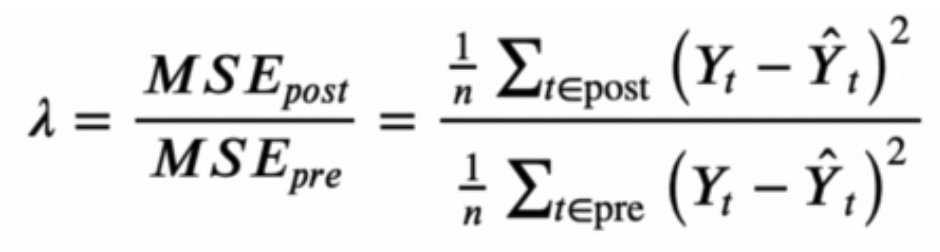


In [20]:
lambdas = {}
for state in states:
    mse_pre = synth_predict(df, SyntheticControl(), state, treatment_year).mse
    mse_tot = np.mean((df[f'Synthetic {state}'] - df[state])**2)
    lambdas[state] = (mse_tot - mse_pre) / mse_pre

print(f"p-value: {np.mean(np.fromiter(lambdas.values(), dtype='float') > lambdas[treated_state]):.400}")

p-value: 0.0


p-value: 0.0 - показывает, что различия между тестом и нашим синтезированным контролем значимы.
Посмотрим на распредление отношения этой метрики по штатам

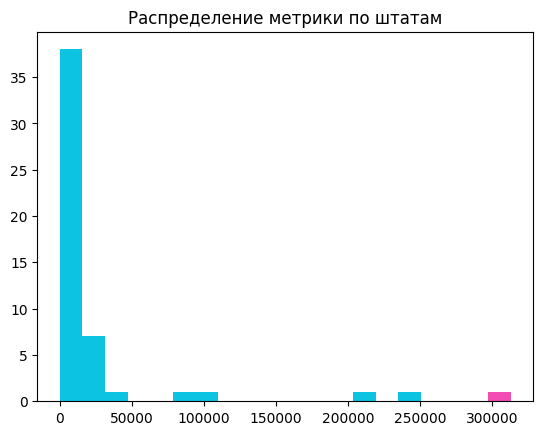

In [ ]:
treated_state = 48
fig, ax = plt.subplots()
_, bins, _ = plt.hist(lambdas.values(), bins=20, color="C1");
plt.hist([lambdas[treated_state]], bins=bins)
plt.title('Распределение метрики по штатам');

# Вывод

Статистика по Техасу очень кардинальна по сравнению с другими штатами. Значение различия между прогнозными значениями и фактическими у него выше, чем у всехостальных шатов, почти у всех них значение метрики более чем в 5 раз ниже, чем у него.

По итогам анализа мы можем сделать вывод о том, что эффект, оказанный строительством тюрем на Техас, значим.

Эффект в абсолютных значениях - 166,654 заключения за весь период после 1993 года, стандартное отклонение - 6,186.37